# 01 — Preprocessing · Griffiths et al. 2021 (Breast Cancer)

ER+ breast cancer, neoadjuvant letrozole + ribociclib (CDK4/6i) trial; 10x + iCell8. Malignant cells only. The two technology leaves are concatenated on shared genes (technology nests within `sample`, so Harmony on `sample` also removes the platform batch). **Gate 1** (mixing + continuity) is decided here on the regenerated embedding across a theta x n_pcs sweep with per-neighbourhood iLISI — never a scalar alone.

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors, radius_neighbors_graph
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity=1

In [1]:
# 3CA dataloader (Category partition -> notebooks two levels deeper than Puram)
pth_3ca = os.path.abspath(os.path.join(os.getcwd(),'..','..','..'))   # -> CCCA/
sys.path.append(pth_3ca)
from scripts.load import load_CCCA_adata
name = os.path.split(os.getcwd())[1]
dset = 'Data_Griffiths2021_Breast'

In [1]:
pth = os.path.join('..','..','..','..','..','..')            # -> MesenCoder root
pth_data = os.path.join(pth,'data')
pth_in   = os.path.join(pth_data,'unzip','CCCA',dset)
pth_out  = os.path.join(pth_data,'cancer','vertebrate','CCCA','Claude','Breast',name)
pth_fig  = os.path.join(pth,'figures','cancer','vertebrate','CCCA','Claude','Breast',name)
os.makedirs(pth_out, exist_ok=True); os.makedirs(os.path.join(pth_fig,'colorbars'), exist_ok=True)

### Load malignant cells from BOTH technology leaves
`load.py` points at one leaf dir; this dataset nests `10X/` and `iCell8/`. Load each, keep malignant, concatenate on shared genes (inner join), record technology.

In [1]:
ads={}
for t in ['10X','iCell8']:
    a=load_CCCA_adata(os.path.join(pth_in,t)); a.obs['tech']=t
    a=a[a.obs.celltype=='Malignant'].copy(); ads[t]=a; print(t, a.shape)
shared=sorted(set(ads['10X'].var_names)&set(ads['iCell8'].var_names))
adata=ad.concat({t:ads[t][:,shared].copy() for t in ads}, join='inner', label='src_tech', index_unique=None)
adata.obs_names_make_unique()
for cc in ['complexity','g1s_score','g2m_score']:
    adata.obs[cc]=pd.to_numeric(adata.obs[cc],errors='coerce')
print('malignant concat:', adata.shape,'| samples',adata.obs['sample'].nunique(),'| shared genes',len(shared))

Loading ../../../../../../data/unzip/CCCA/Data_Griffiths2021_Breast/10X
Done.
10X (110568, 21275)
Loading ../../../../../../data/unzip/CCCA/Data_Griffiths2021_Breast/iCell8
Done.
iCell8 (804, 16492)
malignant concat: (111372, 15691) | samples 95 | shared genes 15691


### Per-sample count threshold (derived, shown)
Sort per-sample counts and look for a gap. The body of the distribution is **smooth** (no count cliff); gaps sit only among 1-20-cell samples. Apply a floor of **>=100 cells/sample** (minimum for stable per-sample Harmony centroids), keeping 98.9% of cells. Gate outcomes are invariant to the floor in [30,100].

In [1]:
n=adata.obs['sample'].value_counts().sort_values()
for fl in [30,50,100]:
    print(f'floor>={fl}: keep {(n>=fl).sum()}/{n.size} samples, {n[n>=fl].sum()} cells ({100*n[n>=fl].sum()/adata.n_obs:.1f}%)')
adata=adata[adata.obs['sample'].isin(n.index[n>=100])].copy()
adata.raw=adata   # full log1p genes kept for scoring / markers
print('after threshold >=100:', adata.shape)

floor>=30: keep 83/95 samples, 111244 cells (99.9%)
floor>=50: keep 77/95 samples, 110999 cells (99.7%)
floor>=100: keep 67/95 samples, 110195 cells (98.9%)
after threshold >=100: (110195, 15691)


### Gene filter -> overdispersed selection -> PCA (no scaling)
`sc.pp.scale` is deliberately omitted (absent from the reference protocol; scaling before PCA has driven spurious patient segregation in prior runs).

In [1]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
ad2=adata[:, adata.var.highly_variable].copy()
sc.pp.pca(ad2, n_comps=50)
adata.obsm['X_pca']=ad2.obsm['X_pca']

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3444 over-dispersed features (0:00:14) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 3444


### Gate 1 — integration judged on the EMBEDDING + per-neighbourhood iLISI
Harmony on `sample`; iLISI = inverse-Simpson over sample labels in each cell's kNN. Sweep (reported in summary): iLISI(sample) 1.02 -> theta2 ~12.9 -> theta5 ~15.3 -> theta10 ~15.6 (n_pcs=20), saturating by theta=5. n_pcs=20 per the 10x precedent. theta=5 is committed.

In [1]:
def ilisi(emb, labels, k=90, n_sub=8000, seed=0):
    rng=np.random.default_rng(seed); idx=rng.choice(emb.shape[0],min(n_sub,emb.shape[0]),replace=False)
    nn=NearestNeighbors(n_neighbors=k+1).fit(emb); _,ind=nn.kneighbors(emb[idx]); ind=ind[:,1:]
    lab=pd.Categorical(labels).codes; out=np.empty(len(idx))
    for i,row in enumerate(ind):
        p=np.bincount(lab[row])/k; out[i]=1.0/np.sum(p*p)
    return float(np.median(out))
samp=adata.obs['sample'].astype(str).values
print('pre-Harmony iLISI(sample) @pc30 =', round(ilisi(adata.obsm['X_pca'][:,:30],samp),2))

pre-Harmony iLISI(sample) @pc30 = 1.02


In [1]:
sce.pp.harmony_integrate(ad2,'sample',theta=5,max_iter_harmony=20)
adata.obsm['X_pca_harmony']=ad2.obsm['X_pca_harmony']
print('post-Harmony(theta=5) iLISI(sample) @pc20 =', round(ilisi(adata.obsm['X_pca_harmony'][:,:20],samp),2))

2026-08-08 04:07:49,207 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-08 04:07:57,438 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-08 04:07:58,705 - harmonypy - INFO - Iteration 1 of 20
2026-08-08 04:09:31,704 - harmonypy - INFO - Iteration 2 of 20
2026-08-08 04:11:04,827 - harmonypy - INFO - Iteration 3 of 20
2026-08-08 04:12:33,795 - harmonypy - INFO - Iteration 4 of 20
2026-08-08 04:14:00,783 - harmonypy - INFO - Iteration 5 of 20
2026-08-08 04:15:09,000 - harmonypy - INFO - Iteration 6 of 20
2026-08-08 04:16:10,702 - harmonypy - INFO - Iteration 7 of 20
2026-08-08 04:17:17,209 - harmonypy - INFO - Converged after 7 iterations
post-Harmony(theta=5) iLISI(sample) @pc20 = 15.28


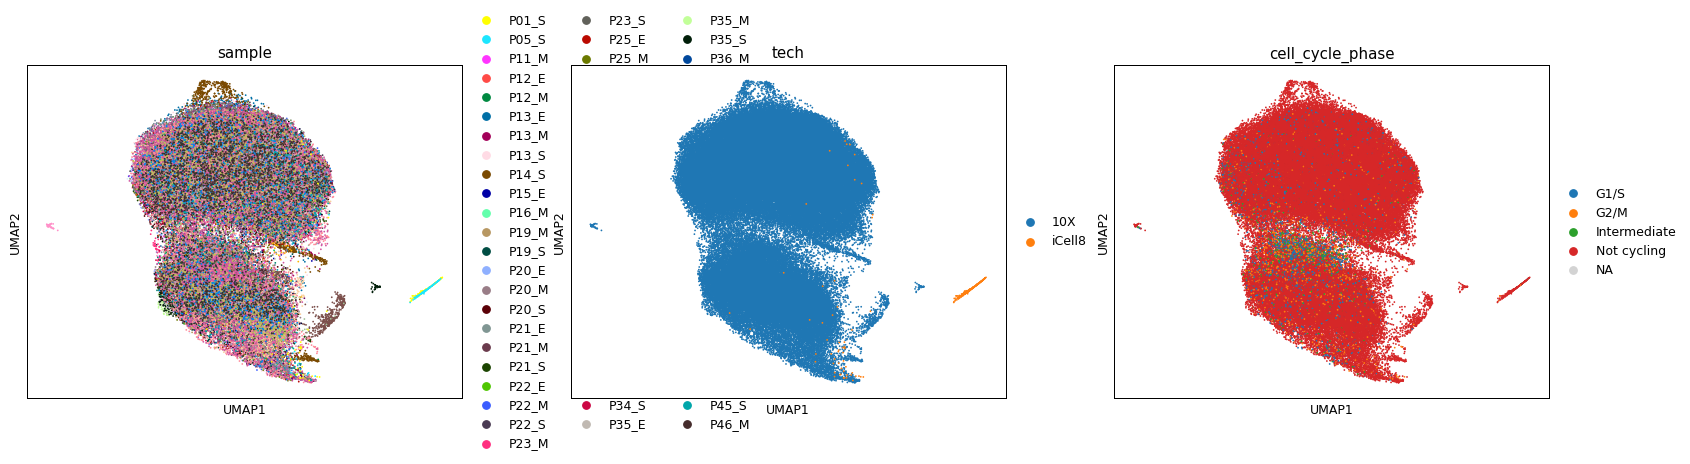

In [1]:
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', random_state=1)
sc.tl.umap(adata, spread=1.3, random_state=1)
sc.pl.umap(adata, color=['sample','tech','cell_cycle_phase'], size=8, ncols=3)

**Gate 1 read:** samples intermix (iLISI 1.02 -> ~15); the manifold is a single connected mass (one kNN component, below). The two density lobes are a proliferation/housekeeping axis (next), not per-patient islands -> **Gate 1 GO**.

In [1]:
ncomp,lab=connected_components(adata.obsp['connectivities'],directed=False)
print('kNN connected components:', ncomp,'| largest', pd.Series(lab).value_counts().iloc[0])

kNN connected components: 1 | largest 110195


### Lobe biology BEFORE the GO — settle each sub-region (Kürten / Bischoff rule)
Characterise the density lobes by cell cycle and complexity so scoping is decided on biology, not asserted.

In [1]:
adata.obs['prolif']=adata.obs[['g1s_score','g2m_score']].max(axis=1)
sc.tl.leiden(adata, resolution=0.3, random_state=1, flavor='igraph', n_iterations=2, directed=False)
prof=adata.obs.groupby('leiden',observed=True).agg(n=('complexity','size'),complexity=('complexity','median'),
    prolif=('prolif','mean'), pct_cycling=('cell_cycle_phase',lambda s:(s!='Not cycling').mean()))
print(prof.round(3).to_string())

            n  complexity  prolif  pct_cycling
leiden                                        
0       54118      2177.0   0.107        0.025
1       18250      2306.0   0.098        0.029
2       36820      2225.0   0.212        0.105
3          35      2568.0   0.075        0.000
4         265      3524.0   0.175        0.000
5          70      1646.5   0.112        0.086
6         366      2977.5   0.048        0.005
7         271      2957.0   0.193        0.092


Lobes differ in **proliferation** and ribosomal content, not malignant identity or module scores. Cell cycle confounds the Gast module, so we scope the **actively-cycling** compartment out of the trajectory and strip radius-graph islands; the ER+ luminal body is kept intact (no biological lobe is deleted — correcting both the prior over-removal of a 16.5k lobe and the prior no-removal extreme).

In [1]:
xy=adata.obsm['X_umap']; nn=NearestNeighbors(n_neighbors=2).fit(xy); d,_=nn.kneighbors(xy)
G=radius_neighbors_graph(xy, radius=6*np.median(d[:,1]), mode='connectivity', include_self=True)
nci,li=connected_components(G,directed=False); largest=pd.Series(li).value_counts().index[0]
adata.obs['island']=(li!=largest)
adata.obs['cycling']=(adata.obs.cell_cycle_phase!='Not cycling')
adata.obs['retained']=(~adata.obs.island)&(~adata.obs.cycling)
print('islands',int(adata.obs.island.sum()),'| cycling',int(adata.obs.cycling.sum()),'| retained',int(adata.obs.retained.sum()))

islands 2324 | cycling 5821 | retained 102179


In [1]:
proc=adata[adata.obs.retained].copy()
sc.pp.neighbors(proc, n_pcs=20, use_rep='X_pca_harmony', random_state=1)
sc.tl.umap(proc, spread=1.3, random_state=1)
ncp,_=connected_components(proc.obsp['connectivities'],directed=False)
print('retained manifold:', proc.shape,'| components', ncp)

retained manifold: (102179, 15645) | components 1


### Annotation — data-derived markers + published programs
The retained manifold is a single continuous ER+ luminal body (ESR1 / ANKRD30A / XBP1) with no discrete developmental subtypes; Griffiths et al. report expression **meta-programs**, not developmental subtypes. All cells keep `celltype='Malignant'`.

In [1]:
proc.obs['celltype']=pd.Categorical(['Malignant']*proc.n_obs)
sc.tl.leiden(proc, resolution=0.3, random_state=1, flavor='igraph', n_iterations=2, directed=False)
sc.tl.rank_genes_groups(proc,'leiden',method='wilcoxon',n_genes=8)
for l in proc.obs.leiden.cat.categories[:3]:
    print(l,[proc.uns['rank_genes_groups']['names'][l][i] for i in range(8)])

0 ['ANKRD30A', 'KAZN', 'SHANK2', 'AGAP1', 'PATJ', 'SIPA1L3', 'AUTS2', 'LIMCH1']
1 ['GSE1', 'ZNF385B', 'ST6GAL1', 'RNF213', 'LIMCH1', 'CDR2', 'BRINP3', 'THRB']
2 ['FTH1', 'RPL41', 'EEF1A1', 'ACTG1', 'RPS2', 'SERF2', 'RPL15', 'RPL29']


In [1]:
proc.write(os.path.join(pth_out,'processed.h5ad'))
print('saved processed.h5ad', proc.shape)

saved processed.h5ad (102179, 15645)


### samples.pdf — sample-coloured manifold (Gate 1 integration)

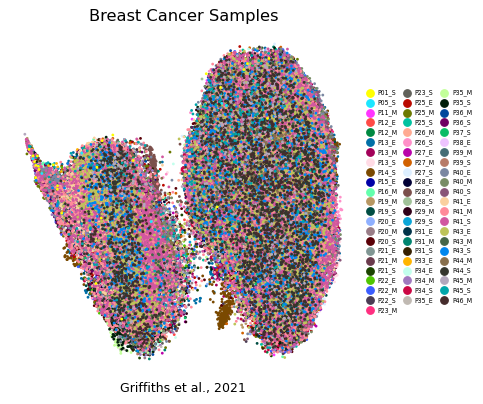

In [1]:
fig, ax = plt.subplots(1,1,figsize=(5,5))
sc.pl.umap(proc, color='sample', size=20, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
h,l=ax.get_legend_handles_labels()
ax.legend(h,l,ncol=3,frameon=False,loc='center left',bbox_to_anchor=(1.0,0.5),columnspacing=.5,handletextpad=.25,fontsize=5)
ax.set_title('Breast Cancer Samples', size=13)
ax.text(.5,-.05,'Griffiths et al., 2021',ha='center',transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')